<a href="https://colab.research.google.com/github/UlfatJarin/Ai-blind-asist-device-demo/blob/main/AI_Blind_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics opencv-python-headless pyttsx3 pytesseract
!apt-get -qq update
!apt-get -qq install tesseract-ocr

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import cv2
import numpy as np
import math
import os
import time

from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Audio

In [ ]:
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")
print("Number of classes:", len(model.names))


YOLO model loaded successfully!
Number of classes: 80


In [ ]:
'''uploaded = files.upload()

image_path = list(uploaded.keys())[0]'''

frame = cv2.imread("/content/Do-Blind-People-Dream.jpg.jpeg")

print("Image loaded:", "/content/Do-Blind-People-Dream.jpg.jpeg")
print("Image size:", frame.shape)

Image loaded: /content/Do-Blind-People-Dream.jpg.jpeg
Image size: (1000, 1500, 3)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def get_direction(x_center, image_width):

    if x_center < image_width * 0.35:
        return "on your left"

    elif x_center > image_width * 0.65:
        return "on your right"

    else:
        return "in front of you"

In [ ]:
def estimate_distance(object_name, box_width):

    known_width = {
        "person": 0.50,
        "chair": 0.45,
        "car": 1.80,
        "bottle": 0.07,
        "backpack": 0.30,
        "laptop": 0.32,
        "cell phone": 0.07,
        "tv": 1.00
    }

    focal_length = {
        "person": 700,
        "chair": 700,
        "car": 700,
        "bottle": 650,
        "backpack": 700,
        "laptop": 700,
        "cell phone": 650,
        "tv": 700
    }

    if object_name not in known_width:
        return None

    if box_width <= 0:
        return None

    distance = (
        known_width[object_name] * focal_length[object_name]
    ) / box_width

    return distance

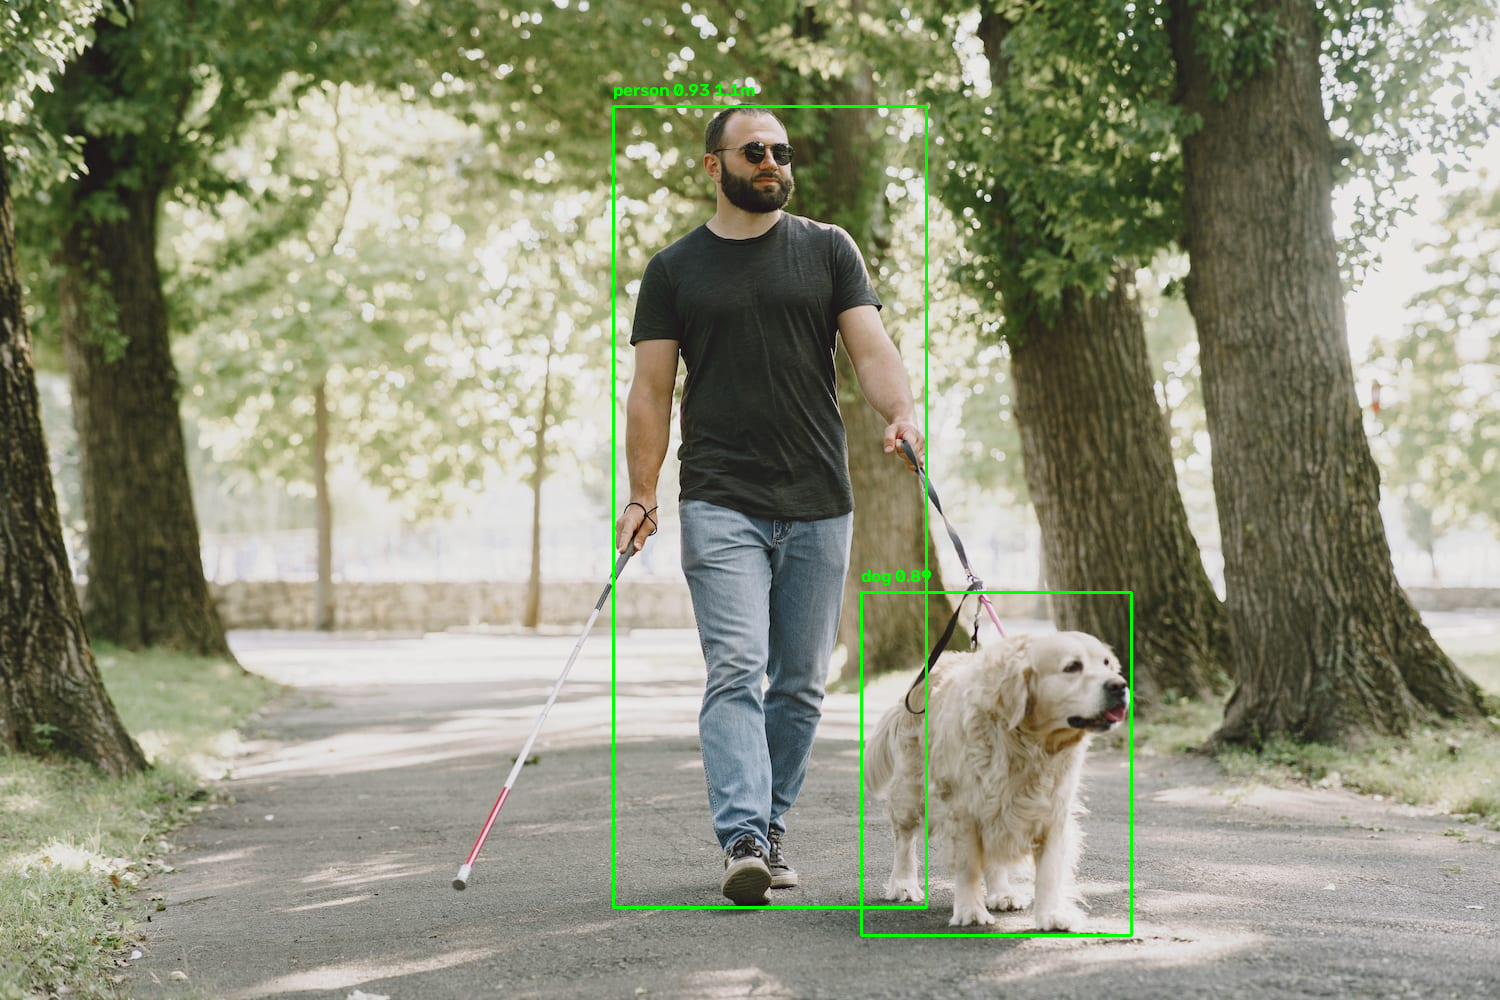


AI Blind Assist Output:
• person 1.1 meters in front of you
• dog on your right


In [ ]:
results = model(
    frame,
    conf=0.40,
    verbose=False
)

image_height, image_width = frame.shape[:2]

messages = []

for result in results:

    for box in result.boxes:

        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0]
        )

        confidence = float(box.conf[0])

        class_id = int(box.cls[0])

        object_name = model.names[class_id]

        box_width = x2 - x1

        x_center = (x1 + x2) / 2

        direction = get_direction(
            x_center,
            image_width
        )

        distance = estimate_distance(
            object_name,
            box_width
        )

        # Draw bounding box
        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Create label
        if distance is not None:

            label = (
                f"{object_name} "
                f"{confidence:.2f} "
                f"{distance:.1f}m"
            )

            message = (
                f"{object_name} "
                f"{distance:.1f} meters "
                f"{direction}"
            )

        else:

            label = (
                f"{object_name} "
                f"{confidence:.2f}"
            )

            message = (
                f"{object_name} "
                f"{direction}"
            )

        messages.append(message)

        cv2.putText(
            frame,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

# Display result
display(
    __import__("PIL").Image.fromarray(
        cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    )
)

print("\nAI Blind Assist Output:")
for msg in messages:
    print("•", msg)

In [ ]:
!pip install -q gTTS

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.


In [ ]:
from gtts import gTTS
from IPython.display import Audio, display

def speak(text):

    print("🔊", text)

    tts = gTTS(
        text=text,
        lang="en"
    )

    filename = "blind_assist_output.mp3"

    tts.save(filename)

    display(
        Audio(
            filename,
            autoplay=True
        )
    )

In [ ]:
objects = []

for result in results:

    for box in result.boxes:

        class_id = int(box.cls[0])

        object_name = model.names[class_id]

        if object_name not in objects:
          objects.append(object_name)


if objects:
  if len(objects) == 1:
    sentence = "I can see " + objects[0]
  else:

    sentence = "I can see " + ", ".join(objects[:-1]) + ", and " + objects[-1]
    speak(sentence)

else:

    speak("I cannot detect any object")

🔊 I can see person, and dog
